# Basic Image Manipulations
In this notebook we will cover how to perform imagetransformation including:
* Accessing and manipulating image pixels
* Image resizing
* Cropping
* Flipping
  

In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import Image
import os

from zipfile import ZipFile 
from urllib.request import urlretrieve
%matplotlib inline

# Python Image Libraries: PIL (Pillow) vs. IPython.display

## 1. Core Differences

| Feature | `from PIL import Image` | `from IPython.display import Image` |
| :--- | :--- | :--- |
| **Primary Purpose** | Modifying, creating, and processing pixel data. | Displaying media inside Jupyter/IPython notebooks. |
| **Object Type** | A live, mutable Python object with pixel manipulation methods. | A static wrapper object that generates HTML/MIME outputs. |
| **Capabilities** | Crop, resize, filter, rotate, draw text, edit pixels. | Embed local files, raw byte data, or live URLs into a notebook cell. |
| **Output Target** | Saved to disk, opened in an OS viewer, or passed to a GUI. | Rendered directly inside web browsers or IDE notebook panels. |

*   **PIL (Pillow)** lets you change the underlying data of the file (e.g., cropping a face, adding watermarks, converting formats).
*   **IPython.display** cannot change pixels; it is simply a presentation layer instructing your notebook browser how to render a file or a web URL (`url="https://..."`) inline.

---

## 2. Resolving the Import Name Conflict

If you import both classes using the exact same name, the compiler gets confused because the second import **overwrites** the first one:

```python
from PIL import Image              # 1. 'Image' points to the PIL module
from IPython.display import Image  # 2. 'Image' is overwritten! It now points to IPython

img = Image.open("photo.jpg")      # ❌ CRASHES: AttributeError: type object 'Image' has no attribute 'open'
```

### Solution A: Explicit Aliasing (Recommended)
You can use the `as` keyword to assign unique, distinct names to both classes so they never conflict. Following Python PEP 8 conventions, use PascalCase for the aliases:

```python
from PIL import Image as PilImage
from IPython.display import Image as IpyImage

# 1. Use PilImage to open and manipulate data
img = PilImage.open("photo.jpg")
resized_img = img.resize((400, 400))
resized_img.save("processed_photo.jpg")

# 2. Use IpyImage to render the file inside your notebook cell
IpyImage(filename="processed_photo.jpg")
```

### Solution B: Avoid Importing IPython's Image Class entirely
If your goal is just to view your PIL modifications inside a Jupyter Notebook, you don't actually need IPython's `Image` class. Jupyter's native `display()` function automatically understands and renders standard PIL objects:

```python
from PIL import Image
from IPython.display import display

# Open and modify with PIL
img = Image.open("photo.jpg")
rotated_img = img.rotate(90)

# Display the live PIL object directly without saving first
display(rotated_img)
```

---


```


[[  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0

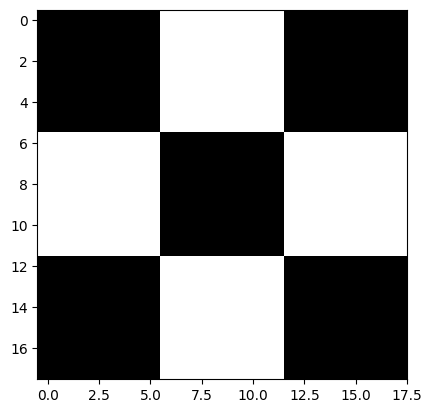

In [3]:
cb_img = cv2.imread("checkerboard_18x18.png", 0)

plt.imshow(cb_img, cmap="gray")
print(cb_img)


plt.show()

__Accessing Individual Pixels__

Let us see how to access a pixel in the image.

For accessing any pixel in a numpy matrix, you have to use matrix notation such as 
matrix[r,c], where the r is the row number and c is the column number. Also note that the matrix is 0-indexed.

For example, if you want to access the first pixel, you need to specify matrix[0,0]. Let us see with some examples. We will print one black pixel from top-left and one white pixel from top-center.

In [4]:
# print the first pixel of the first black box
print(cb_img[0,0])

# print the first white pixel to the right if the first black box
print(cb_img[0,6])



0
255


# Modifying Image Pixels
We can modify the intensity values of pixels in the same manner as described above

[[  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0 200 200   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0 200 200   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0

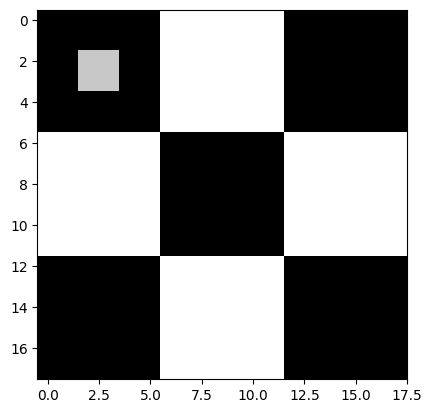

In [8]:
cb_img_copy = cb_img.copy()
cb_img_copy[2,2] = 200
cb_img_copy[2,3] = 200
cb_img_copy[3,2] = 200
cb_img_copy[3,3] = 200

# Same as above
# cb_img_copy[2:3, 2:3] = 200

plt.imshow(cb_img_copy, cmap="gray")
print(cb_img_copy)
plt.show()

In [7]:
cb_img_copy1 = cb_img.copy()
cb_img_copy1[2:4, 2:4] = 200

plt.imshow(cb_img_copy1, cmap="gray")
print(cb_img_copy1)

[[  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0 200 200   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0 200 200   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0

In [16]:
def download_and_unzip(url, save_path):
    print(f"DOwnloading and extracting assets...", end="")

    # Downloading zip files using urllib package.
    urlretrieve(url, save_path)

    try:
        with ZipFile(save_path) as z:
            z.extractall(os.path.split(save_path)[0])
        print("Done")
    except Exception as e:
        print("\nInvalid file.", e)

In [17]:
URL = r"https://www.dropbox.com/s/rys6f1vprily2bg/opencv_bootcamp_assets_NB2.zip?dl=1"

asset_zip_path = os.path.join(os.getcwd(), f"opencv_bootcamp_assets_NB2.zip")

# Download if assets ZIP does not exists:

if not os.path.exists(asset_zip_path):
    download_and_unzip(URL, asset_zip_path)

DOwnloading and extracting assets...Done


# Cropping Images

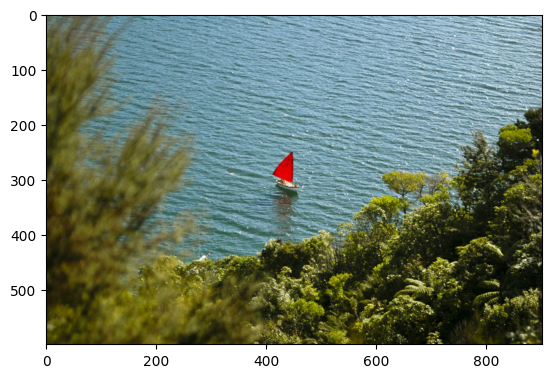

In [18]:
img_NZ_bgr = cv2.imread("New_Zealand_Boat.jpg", cv2.IMREAD_COLOR)
img_NZ_rgb = img_NZ_bgr[:,:,::-1]

plt.imshow(img_NZ_rgb)
plt.show()